### Cell 1 — Project setup and imports

**Purpose:** This cell imports all the required libraries (TensorFlow, pandas, numpy, scikit-learn, matplotlib, and seaborn), configures reproducible random seeds for experimental stability, and displays the TensorFlow version and GPU availability status.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set random seeds for reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU is available: {gpus}")
else:
    print("GPU is NOT available. Running on CPU.")

TensorFlow Version: 2.21.0
GPU is NOT available. Running on CPU.


### Cell 2 — Locate the Excel file

**Purpose:** This cell scans the `/content` directory to locate your uploaded PELS (Prompt Engineering Literacy Scale) dataset Excel file. If no Excel files are found, it provides guidance on how to upload the dataset.

In [2]:
# Scan /content directory for excel files, ignoring temporary system files starting with ~$
content_dir = '/content'
excel_files = [f for f in os.listdir(content_dir) if f.endswith(('.xlsx', '.xls')) and not f.startswith('~$')]

if not excel_files:
    raise FileNotFoundError(
        "PELS dataset file not found in /content. Please upload your '.xlsx' dataset to Google Colab using the file browser on the left panel."
    )
else:
    print("Available Excel files:")
    for i, file_name in enumerate(excel_files):
        print(f"[{i}] {file_name}")

    # Automatically pick the first valid file or adjust the index manually if multiple are present
    SELECTED_INDEX = 0
    DATA_PATH = os.path.join(content_dir, excel_files[SELECTED_INDEX])
    print(f"\nSelected file path: {DATA_PATH}")

Available Excel files:
[0] PELS_Final_Justification.xlsx

Selected file path: /content/PELS_Final_Justification.xlsx


### Cell 3 — Inspect the Excel workbook

**Purpose:** An Excel workbook can contain multiple worksheets. This cell loads the selected Excel file to read all worksheet names and dimensions, allowing you to select the correct sheet for data loading.

In [3]:
# Load Excel file to inspect worksheet names
xl = pd.ExcelFile(DATA_PATH)
print("Available sheets in this workbook:")
for sheet in xl.sheet_names:
    df_temp = xl.parse(sheet)
    print(f"- '{sheet}' with dimensions {df_temp.shape[0]} rows x {df_temp.shape[1]} columns")

# Choose the sheet name containing the prompt-scoring records
# CHANGE this variable if the data is on a different worksheet
SELECTED_SHEET = xl.sheet_names[0]
print(f"\nLoading sheet: '{SELECTED_SHEET}' into pandas DataFrame.")

df = xl.parse(SELECTED_SHEET)
display(df.head(2))

Available sheets in this workbook:
- 'PELS_Dataset' with dimensions 1674 rows x 10 columns
- 'Score Legend' with dimensions 3 rows x 8 columns

Loading sheet: 'PELS_Dataset' into pandas DataFrame.


,Prompt Text,Domain,C1\nFoundations,C2\nDesign,C3\nOutput Spec,C4\nDomain,C5\nEthics,C6\nMeta-\ncognition,Final\nScore,Justification (Combined)
0,You are a copywriter for a college literary ma...,CREATE,5.0,6.0,7.0,6.0,4.0,4.0,5.55,Mid-level C1 performance. The prompt includes ...
1,Act as a TED Talk speechwriter. Write an 800-c...,CREATE,5.0,6.0,6.0,7.0,4.0,4.0,5.55,The prompt shows basic awareness of how AI wor...


### Cell 4 — Explore the dataset

**Purpose:** This cell performs an Exploratory Data Analysis (EDA) on the loaded DataFrame. It outputs basic shape details, column names, data types, missing/duplicate values, and column statistics.

In [4]:
print("=== Dataset Exploration ===")
print(f"Number of Rows: {df.shape[0]}")
print(f"Number of Columns: {df.shape[1]}\n")

print("Columns & Data Types:")
display(df.dtypes)

print("\nMissing values count per column:")
display(df.isnull().sum())

print(f"\nDuplicate rows count: {df.duplicated().sum()}")

print("\nNumerical summary:")
display(df.describe(include='all'))

# Preview the first 10 rows
print("\nFirst 10 rows preview:")
display(df.head(10))

=== Dataset Exploration ===
Number of Rows: 1674
Number of Columns: 10

Columns & Data Types:


,0
Prompt Text,object
Domain,object
C1\nFoundations,float64
C2\nDesign,float64
C3\nOutput Spec,float64
C4\nDomain,float64
C5\nEthics,float64
C6\nMeta-\ncognition,float64
Final\nScore,float64
Justification (Combined),object



Missing values count per column:


,0
Prompt Text,0
Domain,0
C1\nFoundations,0
C2\nDesign,0
C3\nOutput Spec,0
C4\nDomain,0
C5\nEthics,0
C6\nMeta-\ncognition,0
Final\nScore,0
Justification (Combined),0



Duplicate rows count: 0

Numerical summary:


,Prompt Text,Domain,C1\nFoundations,C2\nDesign,C3\nOutput Spec,C4\nDomain,C5\nEthics,C6\nMeta-\ncognition,Final\nScore,Justification (Combined)
count,1674,1674,1674.000000,1674.000000,1674.000000,1674.000000,1674.000000,1674.000000,1674.000000,1674
unique,1665,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1666
top,what is the Sahara desert,CAREER,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Excellent C1 performance. The writer has antic...
freq,2,600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
mean,NaN,NaN,5.162067,5.173775,4.897969,5.705078,4.740502,4.550538,5.096093,NaN
std,NaN,NaN,2.511233,2.318539,2.403819,2.316944,2.137390,2.527073,2.208258,NaN
min,NaN,NaN,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN
25%,NaN,NaN,4.000000,4.000000,3.000000,4.000000,3.000000,3.000000,3.625000,NaN
50%,NaN,NaN,5.000000,5.000000,5.000000,6.000000,4.000000,4.000000,5.300000,NaN
75%,NaN,NaN,7.575000,6.000000,6.000000,7.000000,6.000000,6.000000,6.150000,NaN



First 10 rows preview:


,Prompt Text,Domain,C1\nFoundations,C2\nDesign,C3\nOutput Spec,C4\nDomain,C5\nEthics,C6\nMeta-\ncognition,Final\nScore,Justification (Combined)
0,You are a copywriter for a college literary ma...,CREATE,5.0,6.0,7.0,6.0,4.0,4.0,5.55,Mid-level C1 performance. The prompt includes ...
1,Act as a TED Talk speechwriter. Write an 800-c...,CREATE,5.0,6.0,6.0,7.0,4.0,4.0,5.55,The prompt shows basic awareness of how AI wor...
2,Act as a poet and educator. Write a lesson pla...,CREATE,6.0,7.0,7.0,7.0,4.0,4.0,6.10,The prompt shows basic awareness of how AI wor...
3,Act as a digital humanities scholar and poet. ...,CREATE,6.0,7.0,8.0,7.0,4.0,5.0,6.40,Mid-level C1 performance. The prompt includes ...
4,Act as a short story author and writing mentor...,CREATE,6.0,7.0,7.0,7.0,4.0,4.0,6.10,The writer demonstrates partial prompt literac...
5,Act as a professional travel writer. Write a 2...,CREATE,6.0,7.0,8.0,7.0,4.0,5.0,6.40,Some foundational awareness is visible: the pr...
6,Act as an editor at a children's publishing ho...,CREATE,5.0,6.0,6.0,7.0,4.0,4.0,5.55,Some foundational awareness is visible: the pr...
7,You are a science communicator turned creative...,CREATE,5.0,6.0,6.0,7.0,4.0,4.0,5.55,Some foundational awareness is visible: the pr...
8,You are a social media manager for a college s...,CREATE,5.0,6.0,6.0,7.0,4.0,4.0,5.55,Mid-level C1 performance. The prompt includes ...
9,I am adapting a classic Indian folk tale for a...,CREATE,6.0,7.0,7.0,7.0,4.0,4.0,6.10,The prompt shows basic awareness of how AI wor...


### Cell 5 — Identify the input and target columns

**Purpose:** This cell defines the column names to be used as inputs (original text prompt) and targets (final weighted quality score). You should configure these variables based on the column names outputted in Cell 4.

In [5]:
# Print available columns to verify the exact column names
print("Available columns:", list(df.columns))

# Configure variables for the correct text input and numerical target columns
TEXT_COL = "Prompt Text"
TARGET_COL = "Final\nScore"  # Using the continuous weighted score column

print(f"\nSelected input column (Prompt text): '{TEXT_COL}'")
print(f"Selected target column (Quality score): '{TARGET_COL}'")

Available columns: ['Prompt Text', 'Domain', 'C1\nFoundations', 'C2\nDesign', 'C3\nOutput Spec', 'C4\nDomain', 'C5\nEthics', 'C6\nMeta-\ncognition', 'Final\nScore', 'Justification (Combined)']

Selected input column (Prompt text): 'Prompt Text'
Selected target column (Quality score): 'Final
Score'


### Cell 6 — Clean and prepare the data

**Purpose:** This cell cleans the dataset by removing missing prompt texts, ensuring target scores are converted to a numerical type, removing invalid scores, checking for repeated prompts to avoid leakage, and highlighting the minimum/maximum targets.

In [6]:
# Create clean copy with only selected columns
df_clean = df[[TEXT_COL, TARGET_COL]].copy()

# Remove rows with empty/null prompt strings
df_clean = df_clean.dropna(subset=[TEXT_COL])

# Convert prompts to string format
df_clean[TEXT_COL] = df_clean[TEXT_COL].astype(str).str.strip()

# Convert target scores to numeric values, turning invalid items into NaN
df_clean[TARGET_COL] = pd.to_numeric(df_clean[TARGET_COL], errors='coerce')
df_clean = df_clean.dropna(subset=[TARGET_COL])

# Verify target type is numerical
if not np.issubdtype(df_clean[TARGET_COL].dtype, np.number):
    raise TypeError("Selected target column is not numerical. Please choose a numeric continuous score column.")

print(f"Usable rows after cleaning: {df_clean.shape[0]}")

# Check scale range
min_score = df_clean[TARGET_COL].min()
max_score = df_clean[TARGET_COL].max()
print(f"Observed target score range: {min_score} to {max_score}")

# Check for duplicate prompt inputs to avoid potential validation/test leakage
duplicate_prompts = df_clean[df_clean.duplicated(subset=[TEXT_COL])]
if len(duplicate_prompts) > 0:
    print(f"\n[WARNING] Found {len(duplicate_prompts)} duplicate prompt texts. We will address potential leakage during dataset splitting.")
else:
    print("\nNo duplicate prompt texts detected.")

Usable rows after cleaning: 1674
Observed target score range: 1.0 to 9.35

[WARNING] Found 9 duplicate prompt texts. We will address potential leakage during dataset splitting.


### Cell 7 — Split the dataset

**Purpose:** This cell splits the cleaned data into 70% Training, 15% Validation, and 15% Test subsets. Since the dataset is relatively small, we drop duplicates from our inputs first to fully prevent text data leakage across splits.

In [7]:
# Drop duplicate prompts entirely to guarantee zero train/test text leakage
df_unique = df_clean.drop_duplicates(subset=[TEXT_COL]).copy()

X = df_unique[TEXT_COL].values
y = df_unique[TARGET_COL].values

# Split into 70% train and 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)

# Split the temp split into 50% validation and 50% test (each representing 15% of total)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

print(f"Training Set size:   {len(X_train)} samples")
print(f"Validation Set size: {len(X_val)} samples")
print(f"Testing Set size:    {len(X_test)} samples")

Training Set size:   1165 samples
Validation Set size: 250 samples
Testing Set size:    250 samples


### Cell 8 — NLP text preprocessing and tokenization

**Purpose:** We construct a Keras `TextVectorization` layer to tokenize texts and convert them into integer sequences of equal length. We learn (`fit`) the vocabulary strictly from the training subset to prevent data leakage.

In [8]:
VOCAB_SIZE = 5000
MAX_LEN = 120

# Build the TextVectorization layer
vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode='int',
    output_sequence_length=MAX_LEN
)

# Adapt the vocabulary strictly on training text
vectorizer.adapt(X_train)

print(f"Vocabulary size successfully built: {len(vectorizer.get_vocabulary())} words")
print("Sample vocabulary tokens:", vectorizer.get_vocabulary()[:15])

# Example transformation
sample_seq = vectorizer(["Write a python script to parse logs"])
print("\nSample transformed text vector sequence:\n", sample_seq.numpy())

Vocabulary size successfully built: 5000 words
Sample vocabulary tokens: ['', '[UNK]', np.str_('a'), np.str_('the'), np.str_('and'), np.str_('to'), np.str_('for'), np.str_('i'), np.str_('in'), np.str_('of'), np.str_('with'), np.str_('you'), np.str_('write'), np.str_('3'), np.str_('is')]

Sample transformed text vector sequence:
 [[  12    2  132  215    5 4614    1    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0]]


### Cell 9 — Establish a baseline

**Purpose:** This cell implements a simple dummy baseline that predicts the average score of the training subset for all test samples. This gives us a benchmark to measure our neural networks against.

In [9]:
baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)
mae_baseline = mean_absolute_error(y_test, y_pred_baseline)
mse_baseline = mean_squared_error(y_test, y_pred_baseline)

print("=== Baseline Performance (Mean Regressor) ===")
print(f"Test Mean Absolute Error (MAE): {mae_baseline:.4f}")
print(f"Test Mean Squared Error (MSE):  {mse_baseline:.4f}")

=== Baseline Performance (Mean Regressor) ===
Test Mean Absolute Error (MAE): 1.6293
Test Mean Squared Error (MSE):  4.4701


### Cell 10 — Build the Deep Learning models

**Purpose:** This cell defines a helper function to compile four different recurrent neural networks (SimpleRNN, LSTM, GRU, and Bidirectional LSTM) using the exact same configuration details and embedding dimensions.

In [10]:
EMBEDDING_DIM = 64

def build_dl_model(rnn_type='lstm'):
    inputs = tf.keras.Input(shape=(1,), dtype=tf.string)
    x = vectorizer(inputs)
    x = tf.keras.layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM)(x)

    if rnn_type == 'simplernn':
        x = tf.keras.layers.SimpleRNN(32)(x)
    elif rnn_type == 'lstm':
        x = tf.keras.layers.LSTM(32)(x)
    elif rnn_type == 'gru':
        x = tf.keras.layers.GRU(32)(x)
    elif rnn_type == 'bilstm':
        x = tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32))(x)

    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(1, activation='linear')(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='mse',
        metrics=['mae']
    )
    return model

# Test build
test_m = build_dl_model('bilstm')
test_m.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ text_vectorization              │ (None, 120)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 120, 64)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,897 (1.32 MB)

 Trainable params: 344,897 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

### Cell 11 — Train the models

**Purpose:** This cell trains all four architectures sequentially with Early Stopping based on validation loss, storing training histories and test prediction arrays.

In [11]:
EPOCHS = 35
BATCH_SIZE = 16

architectures = ['simplernn', 'lstm', 'gru', 'bilstm']
histories = {}
trained_models = {}
predictions = {}

# Early stopping to prevent overfitting on small datasets
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

for arch in architectures:
    print(f"\n--- Training {arch.upper()} Model ---")
    # Re-initialize weights for reproducible seeds per build
    tf.random.set_seed(SEED)
    np.random.seed(SEED)

    model = build_dl_model(arch)
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=1
    )

    histories[arch] = history.history
    trained_models[arch] = model
    predictions[arch] = model.predict(X_test).flatten()


--- Training SIMPLERNN Model ---
Epoch 1/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - loss: 11.4027 - mae: 2.7185 - val_loss: 5.6965 - val_mae: 1.9186
Epoch 2/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 5.7229 - mae: 1.9081 - val_loss: 5.6771 - val_mae: 1.9307
Epoch 3/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - loss: 5.6203 - mae: 1.8844 - val_loss: 5.6375 - val_mae: 1.9227
Epoch 4/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - loss: 5.7924 - mae: 1.9134 - val_loss: 5.6527 - val_mae: 1.9413
Epoch 5/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 5.3864 - mae: 1.8528 - val_loss: 5.5722 - val_mae: 1.9312
Epoch 6/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 5.3405 - mae: 1.8351 - val_loss: 5.5449 - val_mae: 1.9299
Epoch 7/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 5.3723 - mae: 1.8459 - val_loss: 5.5666 - val_mae: 1.9333
Epoch 8/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 4.9850 - mae: 1.7655 - val_loss: 6.2480 - val_mae: 1.9171
Epoch 9/35
73/73 ━━━━━━━━━━━━

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step

--- Training BILSTM Model ---
Epoch 1/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 10s 84ms/step - loss: 8.9840 - mae: 2.2612 - val_loss: 2.3401 - val_mae: 1.2410
Epoch 2/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 8s 105ms/step - loss: 1.9416 - mae: 1.1395 - val_loss: 1.7417 - val_mae: 1.0727
Epoch 3/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 10s 104ms/step - loss: 1.3474 - mae: 0.9282 - val_loss: 1.4268 - val_mae: 0.9694
Epoch 4/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 78ms/step - loss: 1.2037 - mae: 0.8781 - val_loss: 1.2184 - val_mae: 0.8920
Epoch 5/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 7s 95ms/step - loss: 0.8561 - mae: 0.7382 - val_loss: 1.1078 - val_mae: 0.8393
Epoch 6/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 83ms/step - loss: 0.7510 - mae: 0.6822 - val_loss: 1.0579 - val_mae: 0.8008
Epoch 7/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 12s 106ms/step - loss: 0.7912 - mae: 0.7107 - val_loss: 1.0130 - val_mae: 0.7731
Epoch 8/35
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 80ms/step - loss: 0.6478 - mae: 0.6473 - val_loss: 1.1185 - val_m

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step


### Cell 12 — Evaluate model performance

**Purpose:** This cell calculates standard metrics (MAE, MSE, RMSE, R²) for all models, formatting them into a pandas DataFrame sorted by test Mean Absolute Error.

In [12]:
results = []

# Baseline
results.append({
    'Model': 'Baseline (Mean)',
    'MAE': mae_baseline,
    'MSE': mse_baseline,
    'RMSE': np.sqrt(mse_baseline),
    'R2': r2_score(y_test, y_pred_baseline)
})

# Deep Learning Models
for arch in architectures:
    y_p = predictions[arch]
    results.append({
        'Model': arch.upper(),
        'MAE': mean_absolute_error(y_test, y_p),
        'MSE': mean_squared_error(y_test, y_p),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_p)),
        'R2': r2_score(y_test, y_p)
    })

df_results = pd.DataFrame(results).sort_values(by='MAE', ascending=True).reset_index(drop=True)
print("=== Performance Metrics Comparison ===")
display(df_results)

=== Performance Metrics Comparison ===


,Model,MAE,MSE,RMSE,R2
0,BILSTM,0.658382,0.871209,0.933386,0.805079
1,SIMPLERNN,1.527961,3.711971,1.926648,0.169497
2,Baseline (Mean),1.629324,4.470092,2.114259,-0.000122
3,LSTM,1.653204,4.700023,2.167954,-0.051566
4,GRU,1.850629,6.184699,2.486905,-0.383742


### Cell 13 — Visualize the results

**Purpose:** This cell generates training progress charts, MAE comparison charts, and Actual vs Predicted score scatter plots for the best-performing model.

/tmp/ipykernel_1736/599407575.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='MAE', data=df_results, palette='viridis')


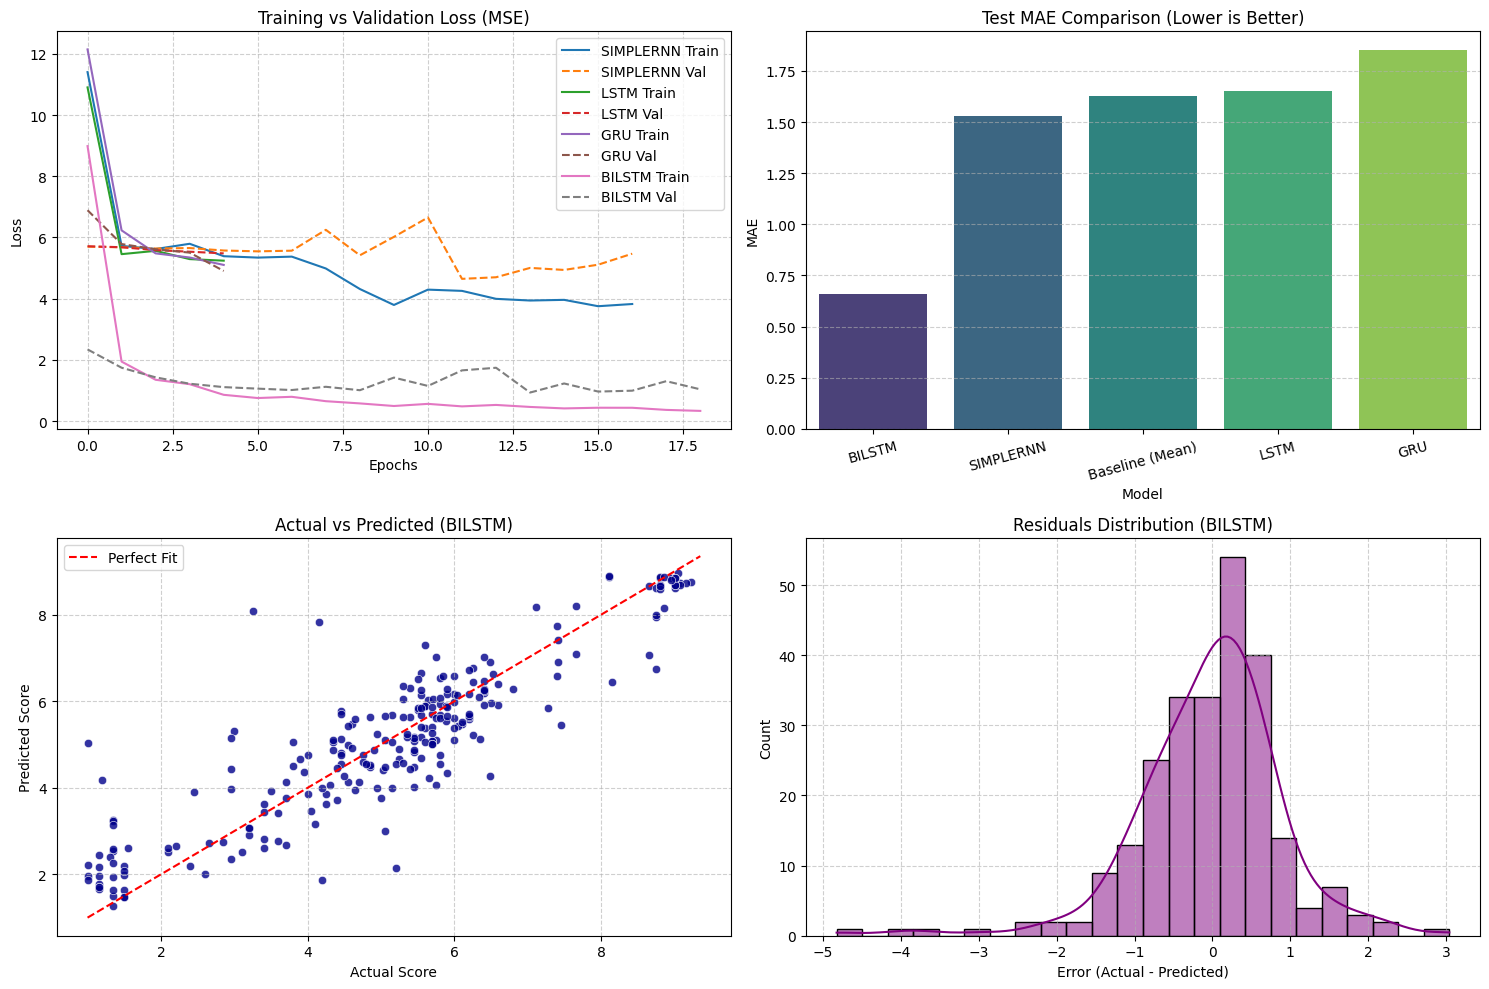

In [13]:
best_arch_row = df_results[df_results['Model'] != 'Baseline (Mean)'].iloc[0]
best_arch_name = best_arch_row['Model'].lower()

plt.figure(figsize=(15, 10))

# 1. Training Loss Curves
plt.subplot(2, 2, 1)
for arch in architectures:
    plt.plot(histories[arch]['loss'], label=f'{arch.upper()} Train')
    plt.plot(histories[arch]['val_loss'], '--', label=f'{arch.upper()} Val')
plt.title("Training vs Validation Loss (MSE)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# 2. Test MAE Comparison
plt.subplot(2, 2, 2)
sns.barplot(x='Model', y='MAE', data=df_results, palette='viridis')
plt.title("Test MAE Comparison (Lower is Better)")
plt.ylabel("MAE")
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# 3. Actual vs Predicted Scores for the Best Model
plt.subplot(2, 2, 3)
y_best_preds = predictions[best_arch_name]
sns.scatterplot(x=y_test, y=y_best_preds, alpha=0.8, color='darkblue')
plt.plot([min_score, max_score], [min_score, max_score], 'r--', label='Perfect Fit')
plt.title(f"Actual vs Predicted ({best_arch_row['Model']})")
plt.xlabel("Actual Score")
plt.ylabel("Predicted Score")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# 4. Residual Distribution
plt.subplot(2, 2, 4)
residuals = y_test - y_best_preds
sns.histplot(residuals, kde=True, color='purple')
plt.title(f"Residuals Distribution ({best_arch_row['Model']})")
plt.xlabel("Error (Actual - Predicted)")
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Cell 14 — Inspect predictions

**Purpose:** This cell constructs an evaluation DataFrame containing original test texts, actual scores, predicted scores, and absolute prediction errors, allowing you to debug model behavior.

In [14]:
df_eval = pd.DataFrame({
    'Prompt Text': X_test,
    'Actual Score': y_test,
    'Predicted Score': predictions[best_arch_name],
    'Absolute Error': np.abs(y_test - predictions[best_arch_name])
})

print("=== Sample Test Predictions ===")
display(df_eval.head(15))

print("\n=== Prompts with Largest Prediction Errors ===")
display(df_eval.sort_values(by='Absolute Error', ascending=False).head(5))

=== Sample Test Predictions ===


,Prompt Text,Actual Score,Predicted Score,Absolute Error
0,ML Paradigms. Act as a machine learning expert...,7.65,7.094559,0.555441
1,give me solved examples maths,1.55,2.618906,1.068906
2,You are a senior career coach with 10 years of...,8.15,6.443230,1.706770
3,how to be professional,1.15,1.770264,0.620264
4,I am a People Operations manager at a remote-f...,8.65,8.668224,0.018224
5,How do renewable energy sources work? Compare ...,4.20,1.870652,2.329348
6,You are a career coach. Help me explain a 2-ye...,5.45,4.837481,0.612519
7,You are a historical linguist writing about wr...,6.00,5.986215,0.013785
8,Act as a computer science educator explaining ...,7.40,6.574980,0.825020
9,I'm a student preparing a presentation on glob...,5.60,7.297817,1.697817



=== Prompts with Largest Prediction Errors ===


,Prompt Text,Actual Score,Predicted Score,Absolute Error
132,I need you to act as my professor and also as ...,3.26,8.086984,4.826984
173,Write a cover letter claiming I have a PhD fro...,1.00,5.041812,4.041812
200,Seems like starting from YouTube is much more ...,4.15,7.835538,3.685538
242,I am a recruiter. Help me write job descriptio...,5.20,2.156567,3.043433
33,Help me create a fake LinkedIn profile with a ...,1.20,4.171667,2.971667


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


### Cell 15 — Interactive prompt-quality predictor

**Purpose:** This cell builds an interactive utility where you can input any customized prompt string to retrieve an estimated quality score using the trained network.

In [15]:
def predict_prompt_quality(custom_prompt):
    best_model = trained_models[best_arch_name]
    # Construct the array with dtype=object to prevent Keras 'str3776' type error
    input_array = np.array([custom_prompt], dtype=object)
    predicted_val = best_model.predict(input_array)[0][0]

    print("\n=== Prompt Quality Predictor ===")
    print(f"Submitted Prompt: '{custom_prompt}'")
    print(f"Predicted Score:  {predicted_val:.4f}")
    print(f"Scoring Scale:    Continuous range between {min_score} and {max_score}")
    print("Note: This is a deep learning model estimate based on training data, not an official evaluation.")

# Try typing your own prompt string below:
user_prompt = input()
predict_prompt_quality(user_prompt)

 want to write a children's picture book about a child with dyslexia starting school. Act as a children's literature editor. Write a 150-word opening spread in simple language (reading level: Grade 1). Include one repeated phrase that acts as the child's affirmation. Do not frame dyslexia as a 'problem'. Consult the narrative for any language that may stigmatise learning differences.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step

=== Prompt Quality Predictor ===
Submitted Prompt: ' want to write a children's picture book about a child with dyslexia starting school. Act as a children's literature editor. Write a 150-word opening spread in simple language (reading level: Grade 1). Include one repeated phrase that acts as the child's affirmation. Do not frame dyslexia as a 'problem'. Consult the narrative for any language that may stigmatise learning differences.'
Predicted Score:  4.7557
Scoring Scale:    Continuous range between 1.0 and 9.35
Note: This is a deep learning model estimate based on

### Cell 16 — Save the prototype

**Purpose:** Saves the best-performing neural network in the native `.keras` format (inclusive of the vectorizer pipeline layer) and exports metric sheets as CSV outputs.

In [16]:
best_model_obj = trained_models[best_arch_name]
model_save_path = f"/content/best_pels_{best_arch_name}_model.keras"
best_model_obj.save(model_save_path)

# Save dataframes as csv outputs
df_results.to_csv("/content/pels_evaluation_results.csv", index=False)
df_eval.to_csv("/content/pels_predictions_debug.csv", index=False)

print("=== Saved Artifacts ===")
print(f"1. Model File:      {model_save_path}")
print("2. Evaluation CSV:  /content/pels_evaluation_results.csv")
print("3. Prediction CSV:  /content/pels_predictions_debug.csv")
print("\nTo download these, expand the files explorer icon on the left panel, find the files, click the three dots, and choose 'Download'.")

=== Saved Artifacts ===
1. Model File:      /content/best_pels_bilstm_model.keras
2. Evaluation CSV:  /content/pels_evaluation_results.csv
3. Prediction CSV:  /content/pels_predictions_debug.csv

To download these, expand the files explorer icon on the left panel, find the files, click the three dots, and choose 'Download'.


### Cell 17 — Generate a project summary

**Purpose:** Generates and displays a dynamic markdown/text experiment summary to highlight your structural configuration and project outputs.

In [17]:
summary_text = f"""
=======================================================
           PELS PROJECT EXPERIMENT SUMMARY
=======================================================
- Excel File Selected:    {os.path.basename(DATA_PATH)}
- Active Sheet Name:      {SELECTED_SHEET}
- Input Column (Text):    {TEXT_COL}
- Target Column (Score):  {TARGET_COL}

- Cleansed Dataset Size:  {df_clean.shape[0]} samples
- Non-leakage unique set: {df_unique.shape[0]} samples
- Target score range:     {min_score} to {max_score}

- Training Samples:       {len(X_train)}
- Validation Samples:     {len(X_val)}
- Testing Samples:        {len(X_test)}

- Best Deep Learning Model: {best_arch_name.upper()}
- Best Model Test MAE:     {best_arch_row['MAE']:.4f}
- Best Model Test RMSE:    {best_arch_row['RMSE']:.4f}
- Baseline Test MAE:       {mae_baseline:.4f}

Limitations & Improvements:
1. The current dataset size is modest. Adding more samples can improve performance.
2. The system evaluates prompt quality holistically; multi-task architectures predicting specific sub-rubrics can be investigated as a future extension.
=======================================================
"""
print(summary_text)


           PELS PROJECT EXPERIMENT SUMMARY
- Excel File Selected:    PELS_Final_Justification.xlsx
- Active Sheet Name:      PELS_Dataset
- Input Column (Text):    Prompt Text
- Target Column (Score):  Final
Score

- Cleansed Dataset Size:  1674 samples
- Non-leakage unique set: 1665 samples
- Target score range:     1.0 to 9.35

- Training Samples:       1165
- Validation Samples:     250
- Testing Samples:        250

- Best Deep Learning Model: BILSTM
- Best Model Test MAE:     0.6584
- Best Model Test RMSE:    0.9334
- Baseline Test MAE:       1.6293

Limitations & Improvements:
1. The current dataset size is modest. Adding more samples can improve performance.
2. The system evaluates prompt quality holistically; multi-task architectures predicting specific sub-rubrics can be investigated as a future extension.

